# 01 · Разведка данных первого этапа

Что скачалось скриптом `uv run python -m seldon download all` и что в этих данных есть:

1. **UCDP** (Uppsala Conflict Data Program, версия 25.1) — целевая переменная по войнам.
2. **PITF** — replication data к модели Goldstone и др. (2010).
3. **conflictforecast.org** — готовые ежемесячные прогнозы (эталон для сравнения).

Отдельный разрез — постсоветские страны.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import pyreadstat

from seldon import DATA_RAW
from seldon.core.entities import POST_SOVIET, POST_SOVIET_GW, POST_SOVIET_ISO3, GW_TO_SHORT, ISO3_TO_SHORT

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (10, 4)

Matplotlib is building the font cache; this may take a moment.


## 1. UCDP

Три таблицы:

- **GED** (`Georeferenced Event Dataset`) — каждое событие с погибшими: где, когда, кто с кем, сколько погибло (`best` — лучшая оценка, `low`/`high` — границы). С 1989 года.
- **ACD** (`UCDP/PRIO Armed Conflict Dataset`) — конфликты по годам (конфликт = спор с ≥25 погибшими в год), с 1946 года. Тип: 1 — колониальный, 2 — межгосударственный, 3 — внутренний, 4 — внутренний с участием других государств.
- **BRD** (`Battle-Related Deaths`) — погибшие в боях по конфликтам и годам, с 1989.

Коды стран в UCDP — Gleditsch–Ward (`gwno`): Россия 365, Украина 369, Грузия 372 и т.д.

In [2]:
ucdp = DATA_RAW / "ucdp"
ged = pd.read_csv(ucdp / "GEDEvent_v25_1.csv", low_memory=False)
acd = pd.read_csv(ucdp / "UcdpPrioConflict_v25_1.csv", low_memory=False)
brd = pd.read_csv(ucdp / "BattleDeaths_v25_1_conf.csv", low_memory=False)

print(f"GED: {len(ged):,} событий, {ged.year.min()}–{ged.year.max()}, {ged.country.nunique()} стран, "
      f"погибших (best) всего {ged.best.sum():,.0f}")
print(f"ACD: {len(acd):,} строк конфликт-год, {acd.year.min()}–{acd.year.max()}, {acd.conflict_id.nunique()} конфликтов")
print(f"BRD: {len(brd):,} строк конфликт-год, {brd.year.min()}–{brd.year.max()}")

GED: 385,918 событий, 1989–2024, 124 стран, погибших (best) всего 3,957,143
ACD: 2,752 строк конфликт-год, 1946–2024, 303 конфликтов
BRD: 1,586 строк конфликт-год, 1989–2024


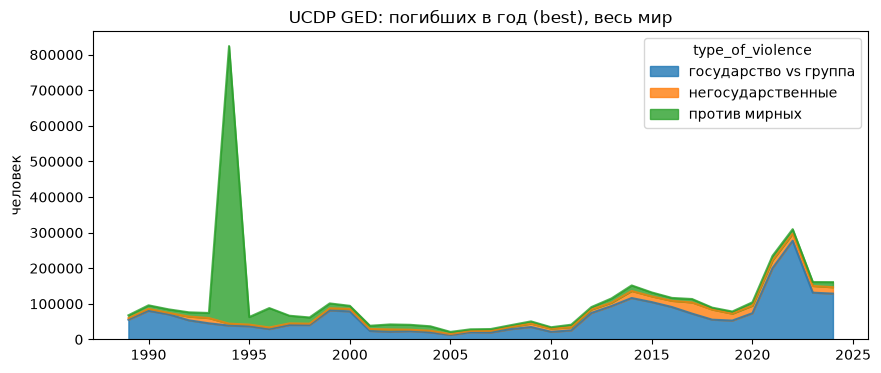

type_of_violence,государство vs группа,негосударственные,против мирных
year,,,
2019,52880,19465,5950
2020,73498,21317,9379
2021,200197,22244,12405
2022,277232,20056,12348
2023,131275,18921,11041
2024,128621,17932,14347


In [3]:
# Погибшие в мире по годам и по типу насилия
# type_of_violence: 1 — государство против вооружённой группы (state-based), 2 — между негосударственными группами, 3 — одностороннее насилие против мирных
tov = {1: "государство vs группа", 2: "негосударственные", 3: "против мирных"}
by_year = ged.groupby(["year", "type_of_violence"]).best.sum().unstack().rename(columns=tov)
ax = by_year.plot(kind="area", stacked=True, alpha=0.8)
ax.set_title("UCDP GED: погибших в год (best), весь мир")
ax.set_ylabel("человек"); ax.set_xlabel("")
plt.show()
by_year.tail(6).astype(int)

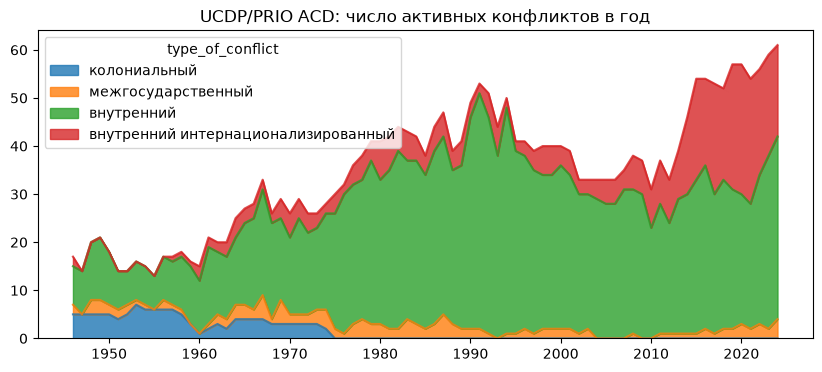

Межгосударственных конфликтов за всю историю: 52 — именно этот тип редкий, а он нам важен (Грузия 2008, Украина 2022, Карабах).


In [4]:
# Конфликты по годам и типам (ACD)
toc = {1: "колониальный", 2: "межгосударственный", 3: "внутренний", 4: "внутренний интернационализированный"}
conf_by_year = acd.groupby(["year", "type_of_conflict"]).conflict_id.nunique().unstack().rename(columns=toc).fillna(0)
ax = conf_by_year.plot(kind="area", stacked=True, alpha=0.8)
ax.set_title("UCDP/PRIO ACD: число активных конфликтов в год"); ax.set_xlabel("")
plt.show()
print("Межгосударственных конфликтов за всю историю:", acd.loc[acd.type_of_conflict == 2, "conflict_id"].nunique(),
      "— именно этот тип редкий, а он нам важен (Грузия 2008, Украина 2022, Карабах).")

### Постсоветские страны в UCDP

In [5]:
ps_ged = ged[ged.country_id.isin(POST_SOVIET_GW)].copy()
ps_ged["страна"] = ps_ged.country_id.map(GW_TO_SHORT)
print(f"Событий в постсоветских странах: {len(ps_ged):,} ({len(ps_ged)/len(ged):.1%} от мира), погибших {ps_ged.best.sum():,.0f}")

deaths = ps_ged.pivot_table(index="страна", columns="year", values="best", aggfunc="sum", fill_value=0).astype(int)
# Показываем ключевые годы: распад СССР, Чечня, 2008, 2014, 2020, 2022+
cols = [1991, 1992, 1993, 1994, 1995, 1996, 1999, 2000, 2004, 2008, 2014, 2015, 2016, 2020, 2022, 2023, 2024]
deaths.loc[deaths.sum(axis=1).sort_values(ascending=False).index, [c for c in cols if c in deaths.columns]]

Событий в постсоветских странах: 37,819 (9.8% от мира), погибших 307,930


year,1991,1992,1993,1994,1995,1996,1999,2000,2004,2008,2014,2015,2016,2020,2022,2023,2024
страна,,,,,,,,,,,,,,,,,
Украина,0,0,0,0,0,0,0,0,0,0,4946,1894,699,196,92615,75393,68116
Россия,340,1,145,485,1910,2764,6197,4333,1317,410,176,86,78,33,67,204,7819
Азербайджан,35,2856,1194,1489,55,5,18,13,8,30,46,63,137,7636,154,442,0
Таджикистан,0,3859,1045,366,368,2797,4,46,0,0,3,0,0,0,87,0,0
Грузия,52,775,1837,0,52,0,0,0,27,621,0,0,0,0,0,1,0
Молдова,0,585,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Узбекистан,0,0,0,0,0,0,50,297,37,0,0,0,0,0,0,0,0
Армения,0,85,37,30,7,0,0,0,0,0,0,16,4,10,154,20,0
Кыргызстан,0,0,0,0,0,0,14,174,0,0,0,1,0,0,68,0,0


In [6]:
# Где в регионе «тихо» в данных, а где нет: суммарно по странам и число лет с ≥25 погибшими
summary = pd.DataFrame({
    "погибших всего": deaths.sum(axis=1),
    "лет с ≥25 погибшими": (deaths >= 25).sum(axis=1),
    "первый год": deaths.apply(lambda r: r[r > 0].index.min() if (r > 0).any() else None, axis=1),
    "последний год": deaths.apply(lambda r: r[r > 0].index.max() if (r > 0).any() else None, axis=1),
}).sort_values("погибших всего", ascending=False)
# Страны без единого события — тоже важная информация
missing = [c["short"] for c in POST_SOVIET if c["short"] not in summary.index]
print("Нет ни одного события в GED:", ", ".join(missing) or "—")
summary

Нет ни одного события в GED: Беларусь, Казахстан, Туркменистан, Эстония, Латвия, Литва


,погибших всего,лет с ≥25 погибшими,первый год,последний год
страна,,,,
Украина,245068,11,2014,2024
Россия,33700,32,1989,2024
Азербайджан,14457,16,1991,2023
Таджикистан,9552,13,1992,2022
Грузия,3432,8,1991,2023
Молдова,585,1,1992,1992
Узбекистан,400,3,1999,2009
Армения,389,4,1992,2023
Кыргызстан,347,4,1999,2022


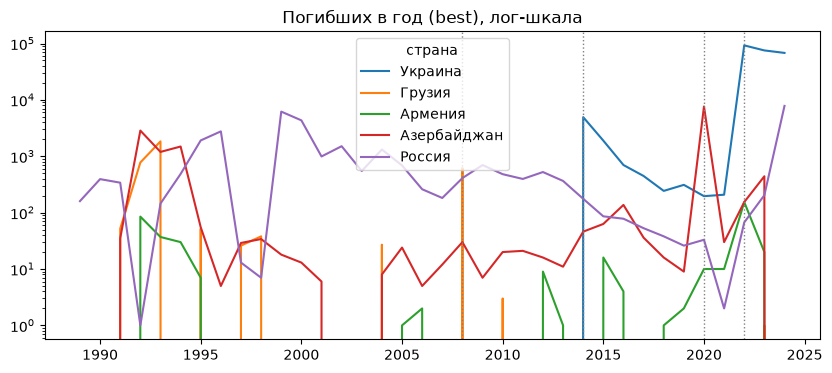

In [7]:
# Динамика по четырём странам, которые будем проверять «вслепую»
focus = ["Украина", "Грузия", "Армения", "Азербайджан", "Россия"]
ax = deaths.loc[focus].T.plot(logy=True)
ax.set_title("Погибших в год (best), лог-шкала"); ax.set_xlabel("")
for y in (2008, 2014, 2020, 2022):
    ax.axvline(y, color="grey", ls=":", lw=1)
plt.show()

In [8]:
# Какие конфликты в регионе знает ACD (конфликт = ≥25 погибших в год)
ps_acd = acd[acd.gwno_loc.astype(str).str.split(",").apply(lambda xs: any(x.strip().isdigit() and int(x) in POST_SOVIET_GW for x in xs))]
ps_conf = (ps_acd.groupby(["conflict_id", "location", "side_a", "side_b", "territory_name"], dropna=False)
           .agg(годы=("year", lambda s: f"{s.min()}–{s.max()}"), лет_активен=("year", "nunique"),
                тип=("type_of_conflict", lambda s: ", ".join(sorted({toc[t] for t in s}))),
                макс_интенсивность=("intensity_level", "max"))
           .reset_index().sort_values("годы"))
print(f"Конфликтов в постсоветских странах: {len(ps_conf)}")
ps_conf

Конфликтов в постсоветских странах: 43


,conflict_id,location,side_a,side_b,territory_name,годы,лет_активен,тип,макс_интенсивность
1,211,Russia (Soviet Union),Government of Russia (Soviet Union),"LNPA, LTS(p)A",Latvia,1946–1946,1,внутренний,1
0,210,Russia (Soviet Union),Government of Russia (Soviet Union),Forest Brothers,Estonia,1946–1948,3,внутренний,1
2,212,Russia (Soviet Union),Government of Russia (Soviet Union),BDPS,Lithuania,1946–1948,3,внутренний,2
3,213,Russia (Soviet Union),Government of Russia (Soviet Union),UPA,Ukraine,1946–1950,5,внутренний,2
4,250,"Hungary, Russia (Soviet Union)",Government of Hungary,Government of Russia (Soviet Union),NaN,1956–1956,1,межгосударственный,2
5,305,"China, Russia (Soviet Union)",Government of China,Government of Russia (Soviet Union),Ussuri river,1969–1969,1,межгосударственный,1
30,431,"Afghanistan, Russia (Soviet Union)",Government of Afghanistan,Government of Russia (Soviet Union),NaN,1979–1979,1,межгосударственный,1
7,377,Russia (Soviet Union),Government of Russia (Soviet Union),APF,Azerbaijan,1990–1990,1,внутренний,1
6,376,Russia (Soviet Union),Government of Russia (Soviet Union),Republic of Armenia,Nagorno-Karabakh,1990–1991,2,внутренний,1
8,380,Georgia,Government of Georgia,National Guard and Mkhedrioni,NaN,1991–1991,1,внутренний,1


## 2. PITF — replication data (Goldstone и др., 2010)

Модель PITF: логистическая регрессия на четырёх переменных, горизонт 2 года.

- `sftptv2a` — тип режима (главный предиктор: частичная демократия с фракционностью);
- `logim` — детская смертность (логарифм, относительно мирового уровня);
- `maccat` — 4+ соседних государств с крупным конфликтом;
- `disp4cat` — дискриминация со стороны государства.

Важно понять, что лежит в файле: полная панель «страна-год» или только выборка.

In [9]:
pitf, meta = pyreadstat.read_dta(DATA_RAW / "pitf" / "PITF-Global-Model-Replication-Data-121709.dta")
print(pitf.shape)
print("Годы:", pitf.year.min(), "–", pitf.year.max(), "| стран:", pitf.sftgcode.nunique())
print("sftpcons (1 = случай начала нестабильности, 0 = контроль):")
print(pitf.sftpcons.value_counts())
print("Строк на страну-год в среднем:", round(len(pitf) / pitf[["sftgcode", "year"]].drop_duplicates().shape[0], 2))
pitf.head()

(1404, 25)
Годы: 1956 – 2003 | стран: 158
sftpcons (1 = случай начала нестабильности, 0 = контроль):
sftpcons
0    1053
1     351
Name: count, dtype: int64
Строк на страну-год в среднем: 1.53


,sftgcode,year,byregn2,group,sftgname,feanctig,sftptv2a,sftpcons,ethherf,relhrel,disp4cat,sftpdur2,floil,maccat,logim,logtpop,logmtn,anocracy,democracy,log_gdpc,miss_ind,glb_ind,cwar_ind,reg_ind,sample
0,AFG,1957,5,1,Afghanistan,0,Full autocracy,0,0.361778,0.616318,0,0,0,0,0.660017,9.106534,4.198705,0,0,5.030438,0,Y,,Y,1.0
1,AFG,1962,5,1,Afghanistan,0,Full autocracy,0,0.361778,0.616318,0,0,0,0,0.618346,9.215427,4.198705,0,0,5.176150,0,Y,Y,,1.0
2,AFG,1970,5,1,Afghanistan,0,Full autocracy,0,0.361778,0.616318,0,0,0,0,0.617802,9.400713,4.198705,0,0,5.480639,0,Y,Y,,1.0
3,AFG,1978,5,1,Afghanistan,0,Full autocracy,1,0.391428,0.616318,0,0,0,0,0.805741,9.592332,4.198705,0,0,5.929589,0,Y,Y,,1.0
4,ALB,1963,3,1,Albania,0,Full autocracy,0,0.904293,0.346207,0,0,0,0,0.018457,7.415175,2.270523,0,0,6.206576,0,Y,Y,,1.0


In [10]:
# Это не полная панель, а «случай–контроль»: к каждому началу нестабильности подобраны контрольные страны того же года.
# Проверим: сколько случаев, сколько контролей на случай, есть ли постсоветские страны.
print("Распределение по `group` (идентификатор пары случай–контроли):")
print(pitf.groupby("group").sftpcons.agg(["size", "sum"]).describe().T[["mean", "min", "max"]])
ps_codes = {"RUS", "UKR", "BLR", "MLD", "GRG", "ARM", "AZE", "KZK", "KYR", "TAJ", "TKM", "UZB", "EST", "LAT", "LIT"}  # коды PITF/Polity
ps_pitf = pitf[pitf.sftgcode.isin(ps_codes)]
print(f"\nПостсоветских строк: {len(ps_pitf)}")
ps_pitf[["sftgcode", "sftgname", "year", "sftpcons", "sftptv2a", "logim", "maccat", "disp4cat"]].sort_values(["sftgcode", "year"])

Распределение по `group` (идентификатор пары случай–контроли):
       mean   min     max
size  468.0  24.0  1104.0
sum   117.0   6.0   276.0

Постсоветских строк: 18


,sftgcode,sftgname,year,sftpcons,sftptv2a,logim,maccat,disp4cat
15,ARM,Armenia,1995,1,Partial democracy without factionalism,-0.299854,1,0
479,ARM,Armenia,1995,1,Partial democracy without factionalism,-0.299854,1,0
949,ARM,Armenia,1995,1,Partial democracy without factionalism,-0.299854,1,0
46,BLR,Belarus,1995,1,Partial democracy with factionalism,-1.077559,0,0
509,BLR,Belarus,1995,1,Partial democracy with factionalism,-1.077559,0,0
975,BLR,Belarus,1995,1,Partial democracy with factionalism,-1.077559,0,0
600,EST,Estonia,1994,0,Partial democracy with factionalism,-0.982441,0,1
1053,EST,Estonia,1996,0,Partial democracy with factionalism,-1.068398,0,1
694,KYR,Kyrgyzstan,1994,0,Full autocracy,0.338885,0,0
1160,KYR,Kyrgyzstan,1994,0,Full autocracy,0.338885,0,0


In [11]:
# Какие переменные и сколько пропусков — чтобы знать, что придётся собирать заново для полной панели
pd.DataFrame({"метка": meta.column_names_to_labels, "пропусков": pitf.isna().sum(), "уникальных": pitf.nunique()})

,метка,пропусков,уникальных
sftgcode,SFTGCODE,0,158
year,YEAR,0,45
byregn2,BYREGN2,0,5
group,GROUP,0,3
sftgname,SFTGNAME,0,158
feanctig,FEANCTIG,0,2
sftptv2a,SFTPTV2A,0,6
sftpcons,SFTPCONS,0,2
ethherf,ETHHERF,7,413
relhrel,RELHREL,7,405


## 3. conflictforecast.org — готовые прогнозы

Файлы `ons_*` — вероятность **начала** (`onset`) насилия на горизонте 3 или 12 месяцев, `int_*` — прогноз интенсивности (лог числа погибших). В каждом файле четыре колонки прогноза:

- `_text` — только по темам новостей;
- `_hist` — только по истории конфликтов;
- `_all` — обе группы признаков вместе;
- `_naive` — наивная базовая модель;
- `_target` — что случилось на самом деле (пусто там, где будущее ещё не наступило).

Плюс признаки, на которых они учились (`ongoing_*`, `past_bestpc_*`, `neighbors_*`, `population`…). Сырых долей тем новостей в выгрузке нет — только их вклад в прогноз.

In [12]:
cf_dir = DATA_RAW / "conflictforecast" / "latest"
cf = pd.read_csv(cf_dir / "conflictforecast_ons_armedconf_12.csv")
cf["date"] = pd.to_datetime(cf.period.astype(str), format="%Y%m")
print(f"{len(cf):,} строк страна-месяц, {cf.isocode.nunique()} стран, {cf.date.min():%Y-%m} – {cf.date.max():%Y-%m}")
print("Доля месяцев с началом вооружённого конфликта (target=1):", round(cf.ons_armedconf_12_target.mean(), 4))
print("Постсоветские страны в файле:", sorted(set(cf.isocode) & POST_SOVIET_ISO3))
print("Нет в файле:", sorted(POST_SOVIET_ISO3 - set(cf.isocode)))

36,746 строк страна-месяц, 182 стран, 2010-01 – 2026-10
Доля месяцев с началом вооружённого конфликта (target=1): 0.1189
Постсоветские страны в файле: ['ARM', 'AZE', 'BLR', 'EST', 'GEO', 'KAZ', 'KGZ', 'LTU', 'LVA', 'MDA', 'RUS', 'TJK', 'TKM', 'UKR', 'UZB']
Нет в файле: []


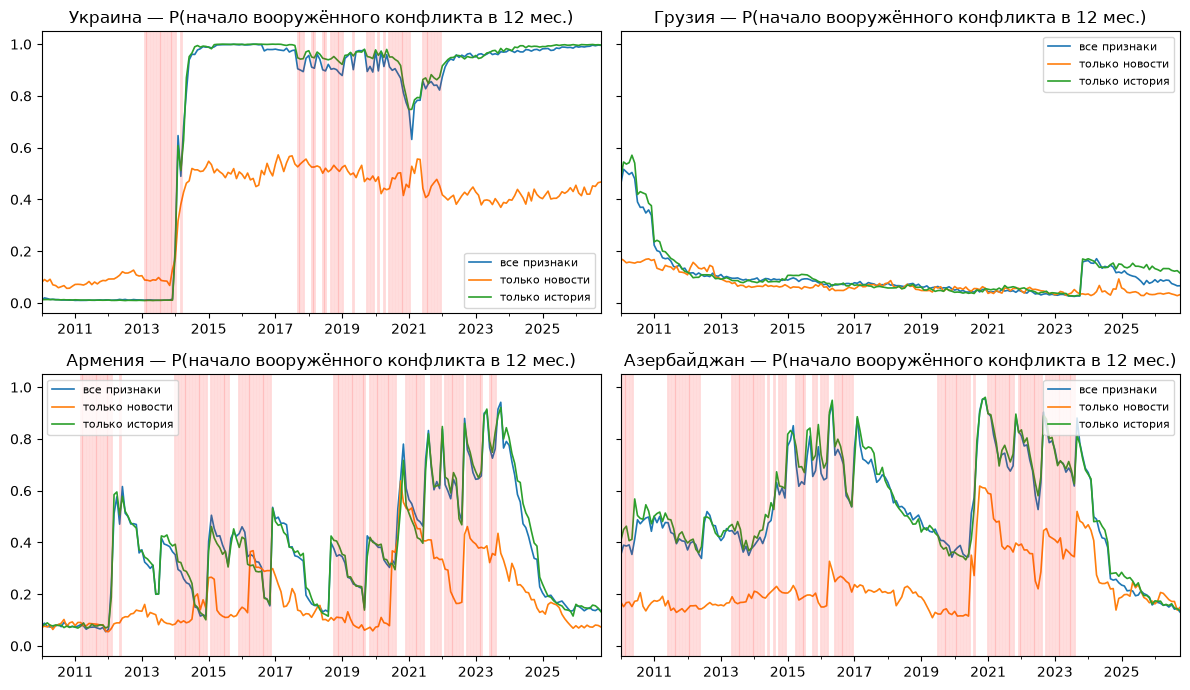

Красные полосы — месяцы, после которых в 12-месячном окне действительно начался вооружённый конфликт.


In [13]:
# Что модель говорила о Грузии, Украине, Армении, Азербайджане — прогноз начала вооружённого конфликта в ближайшие 12 мес.
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, iso in zip(axes.flat, ["UKR", "GEO", "ARM", "AZE"]):
    d = cf[cf.isocode == iso].set_index("date")
    d[["ons_armedconf_12_all", "ons_armedconf_12_text", "ons_armedconf_12_hist"]].rename(
        columns={"ons_armedconf_12_all": "все признаки", "ons_armedconf_12_text": "только новости", "ons_armedconf_12_hist": "только история"}
    ).plot(ax=ax, lw=1.2)
    onsets = d.index[d.ons_armedconf_12_target == 1]
    for o in onsets:
        ax.axvline(o, color="red", alpha=0.15, lw=2)
    ax.set_title(f"{ISO3_TO_SHORT[iso]} — P(начало вооружённого конфликта в 12 мес.)"); ax.set_xlabel("")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Красные полосы — месяцы, после которых в 12-месячном окне действительно начался вооружённый конфликт.")

In [14]:
# Сводка по постсоветским странам: сколько месяцев с началом конфликта и средний прогноз
ps_cf = cf[cf.isocode.isin(POST_SOVIET_ISO3)].copy()
ps_cf["страна"] = ps_cf.isocode.map(ISO3_TO_SHORT)
(ps_cf.groupby("страна")
 .agg(месяцев=("period", "size"), начал_конфликта=("ons_armedconf_12_target", "sum"),
      средний_прогноз_all=("ons_armedconf_12_all", "mean"), макс_прогноз_all=("ons_armedconf_12_all", "max"))
 .sort_values("макс_прогноз_all", ascending=False).round(3))

,месяцев,начал_конфликта,средний_прогноз_all,макс_прогноз_all
страна,,,,
Украина,202,46.0,0.715,1.000
Россия,202,37.0,0.430,0.984
Азербайджан,202,93.0,0.526,0.954
Армения,202,93.0,0.360,0.942
Таджикистан,202,60.0,0.315,0.861
Кыргызстан,202,29.0,0.165,0.636
Грузия,202,0.0,0.104,0.517
Молдова,202,0.0,0.033,0.255
Узбекистан,202,0.0,0.056,0.200


## Выводы разведки

**UCDP.** 386 тыс. событий за 1989–2024, 124 страны. Постсоветские страны — ~10% событий и 308 тыс. погибших, из них 245 тыс. — Украина с 2014. В данных «тихо» для Беларуси, Казахстана, Туркменистана и Балтии (ни одного события). Нюанс кодировки, важный для проверок «вслепую»:

- Грузия 2008 в ACD — не межгосударственная война, а конфликт «Грузия vs Южная Осетия» с участием России (тип 4). Межгосударственных конфликтов за 1946–2024 всего 52.
- Карабах 2020 — «Азербайджан vs Арцах» (тип 3/4), 7,6 тыс. погибших в 2020.
- Украина: Майдан 2014 (внутренний), Донбасс 2014–2021 (тип 4), Россия–Украина 2022– (межгосударственный, 68–93 тыс. погибших в год).

**PITF.** Replication data — это не панель «страна-год», а выборка «случай–контроль»: 351 начало нестабильности и 1053 контроля за 1956–2003, три набора (`group`). Постсоветских строк всего 18, и все за 1994–1996. Значит, повторить модель по статье можно, но чтобы применить её к 2008/2014/2022, четыре признака придётся собрать заново из Polity/V-Dem, WDI (детская смертность) и UCDP (конфликты у соседей).

**conflictforecast.** Готовая панель страна-месяц, 182 страны, 2010-01 – 2026-10, все 15 постсоветских стран на месте. Есть прогнозы четырёх моделей (`text`/`hist`/`all`/`naive`), целевая переменная и признаки истории — готовый эталон. Ограничения: нет 2008 года (Грузия не проверить), нет сырых долей тем новостей. Базовая частота «начала вооружённого конфликта в 12 мес.» — 12% месяцев: это широкое определение начала, нужно разобраться с ним до сравнения.

Подробнее — в `reports/2026-11-07-session-1.md`.